In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
from scipy.special import softmax
from PIL import Image
import pandas as pd
import onnxruntime as ort
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import timm
from timm.data import create_transform
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
TEST_DIR = "../data/Testing"
OUT = Path('../analysis_out'); OUT.mkdir(exist_ok=True)

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [3]:
ckpt = torch.load('../models/best_model.pth')
class_names,cfg = ckpt['classes'],ckpt['cfg']

providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
sess = ort.InferenceSession('../models/best_model.onnx',providers=providers)
print("Runnig on:", sess.get_providers()[0])
print("Input size from training:", cfg["input_size"],"| classes:", len(class_names) )


/tmp/ipykernel_4486/2665942486.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load('../models/best_model.pth')


Runnig on: CUDAExecutionProvider
Input size from training: (3, 299, 299) | classes: 4


In [4]:
from torchvision import transforms
tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
test_ds = ImageFolder(TEST_DIR, transform=tf)

In [5]:
def run_onnx(ds,bs=64):
    loader = DataLoader(ds,batch_size=bs,shuffle=False,num_workers=os.cpu_count())
    logits,labels = [],[]
    for x,y in loader:
        out = sess.run(None,{'input':x.numpy()})[0]
        logits.append(out);labels.append(y.numpy())
    return np.concatenate(logits), np.concatenate(labels)

test_logits, test_labels = run_onnx(test_ds)

In [6]:
idx = np.arange(len(test_labels))
cal_idx, eval_idx = train_test_split(idx, test_size=0.5, stratify=test_labels, random_state=42)

print(f"Test accuracy: {(test_logits.argmax(1) == test_labels).mean():.4f}")
print(f"Calibration half: {len(cal_idx)} | Evaluation half: {len(eval_idx)}")

np.save(OUT/"test_logits.npy", test_logits); np.save(OUT/"test_labels.npy", test_labels)
np.save(OUT/"test_paths.npy", np.array([p for p, _ in test_ds.samples]))
np.save(OUT/"cal_idx.npy", cal_idx); np.save(OUT/"eval_idx.npy", eval_idx)

Test accuracy: 0.9456
Calibration half: 800 | Evaluation half: 800


In [7]:
preds = test_logits.argmax(1)
cm = confusion_matrix(test_labels, preds, labels=range(len(class_names)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

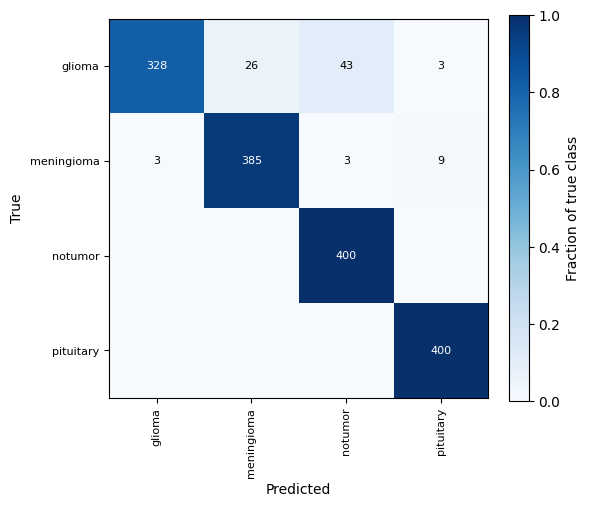

In [8]:
size = max(6, len(class_names) * 0.5)
fig, ax = plt.subplots(figsize=(size, size))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(class_names))); ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=90, fontsize=8)
ax.set_yticklabels(class_names, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")

if len(class_names) <= 20:                       
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm_norm[i, j] > 0.5 else "black")

fig.colorbar(im, fraction=0.046, label="Fraction of true class")
fig.tight_layout()
fig.savefig(OUT/"confusion_matrix.png", dpi=200)
plt.show()

In [9]:
print(classification_report(test_labels, preds, target_names=class_names, digits=3))

              precision    recall  f1-score   support

      glioma      0.991     0.820     0.897       400
  meningioma      0.937     0.963     0.949       400
     notumor      0.897     1.000     0.946       400
   pituitary      0.971     1.000     0.985       400

    accuracy                          0.946      1600
   macro avg      0.949     0.946     0.944      1600
weighted avg      0.949     0.946     0.944      1600



In [10]:
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(
    [(class_names[i], class_names[j], off[i, j]) for i in range(len(class_names)) for j in range(len(class_names)) if off[i, j]],
    key=lambda t: -t[2])

print("Top confused pairs (true -> predicted):")
for t, p, c in pairs[:10]:
    print(f"  {t:20s} -> {p:20s} {c} images")

Top confused pairs (true -> predicted):
  glioma               -> notumor              43 images
  glioma               -> meningioma           26 images
  meningioma           -> pituitary            9 images
  glioma               -> pituitary            3 images
  meningioma           -> glioma               3 images
  meningioma           -> notumor              3 images


In [11]:
paths  = np.load(OUT/"test_paths.npy")
probs = softmax(test_logits, axis=1)
preds = probs.argmax(1)
top2  = np.argsort(-probs, axis=1)[:, :2]

df = pd.DataFrame({
    "path": paths,
    "true": test_labels, "pred": preds,
    "true_name": [class_names[i] for i in test_labels],
    "pred_name": [class_names[i] for i in preds],
    "conf": probs.max(1),                                  # confidence in the predicted class
    "p_true": probs[np.arange(len(test_labels)), test_labels],       # probability given to the correct class
    "true_in_top2": (top2 == test_labels[:, None]).any(1),
})
df["wrong"] = df.true != df.pred
print(f"{df.wrong.sum()} misclassified out of {len(df)}")

87 misclassified out of 1600


In [12]:
def quality(path):
    g = np.asarray(Image.open(path).convert("L").resize((256, 256)), dtype=np.float32)
    lap = 4*g[1:-1,1:-1] - g[:-2,1:-1] - g[2:,1:-1] - g[1:-1,:-2] - g[1:-1,2:]
    return lap.var(), g.mean()          # sharpness, brightness

q = np.array([quality(p) for p in df.path])
df["sharpness"], df["brightness"] = q[:, 0], q[:, 1]

In [13]:
lo_sharp = np.percentile(df.sharpness, 10)
lo_b, hi_b = np.percentile(df.brightness, 5), np.percentile(df.brightness, 95)

def cause(r):
    if r.conf >= 0.9:
        return "confident_wrong"           
    if r.sharpness <= lo_sharp:
        return "blurry_low_detail"
    if r.brightness <= lo_b or r.brightness >= hi_b:
        return "bad_exposure"
    if r.true_in_top2:
        return "near_miss_similar_classes"
    if r.conf < 0.5:
        return "low_confidence"
    return "other"

df["cause"] = ""
df.loc[df.wrong, "cause"] = df[df.wrong].apply(cause, axis=1)
err = df[df.wrong].copy()
print(err.cause.value_counts())

cause
confident_wrong              58
near_miss_similar_classes    13
other                        10
bad_exposure                  3
blurry_low_detail             3
Name: count, dtype: int64


In [14]:
err.drop(columns="wrong").to_csv(OUT/"misclassified.csv", index=False)
print(err.groupby("cause")[["conf", "p_true"]].mean().round(3))

                            conf  p_true
cause                                   
bad_exposure               0.624   0.000
blurry_low_detail          0.695   0.190
confident_wrong            0.983   0.010
near_miss_similar_classes  0.747   0.237
other                      0.719   0.016


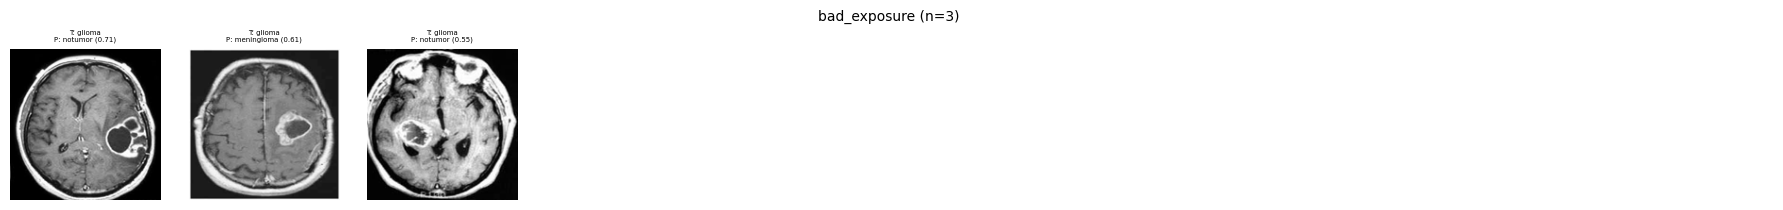

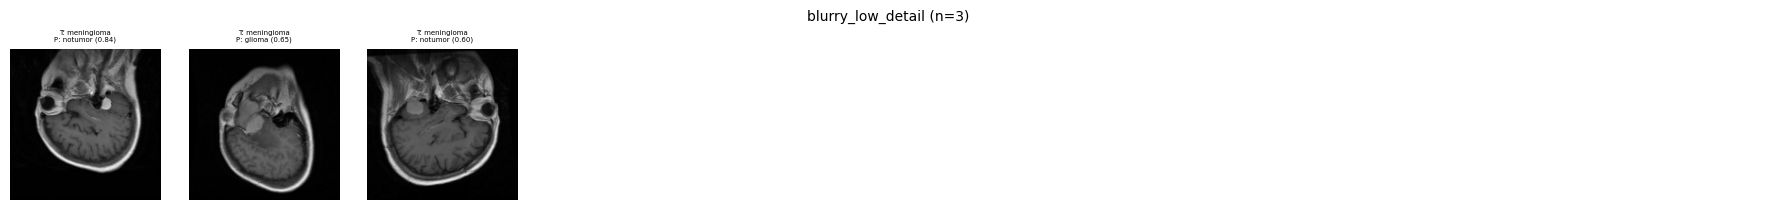

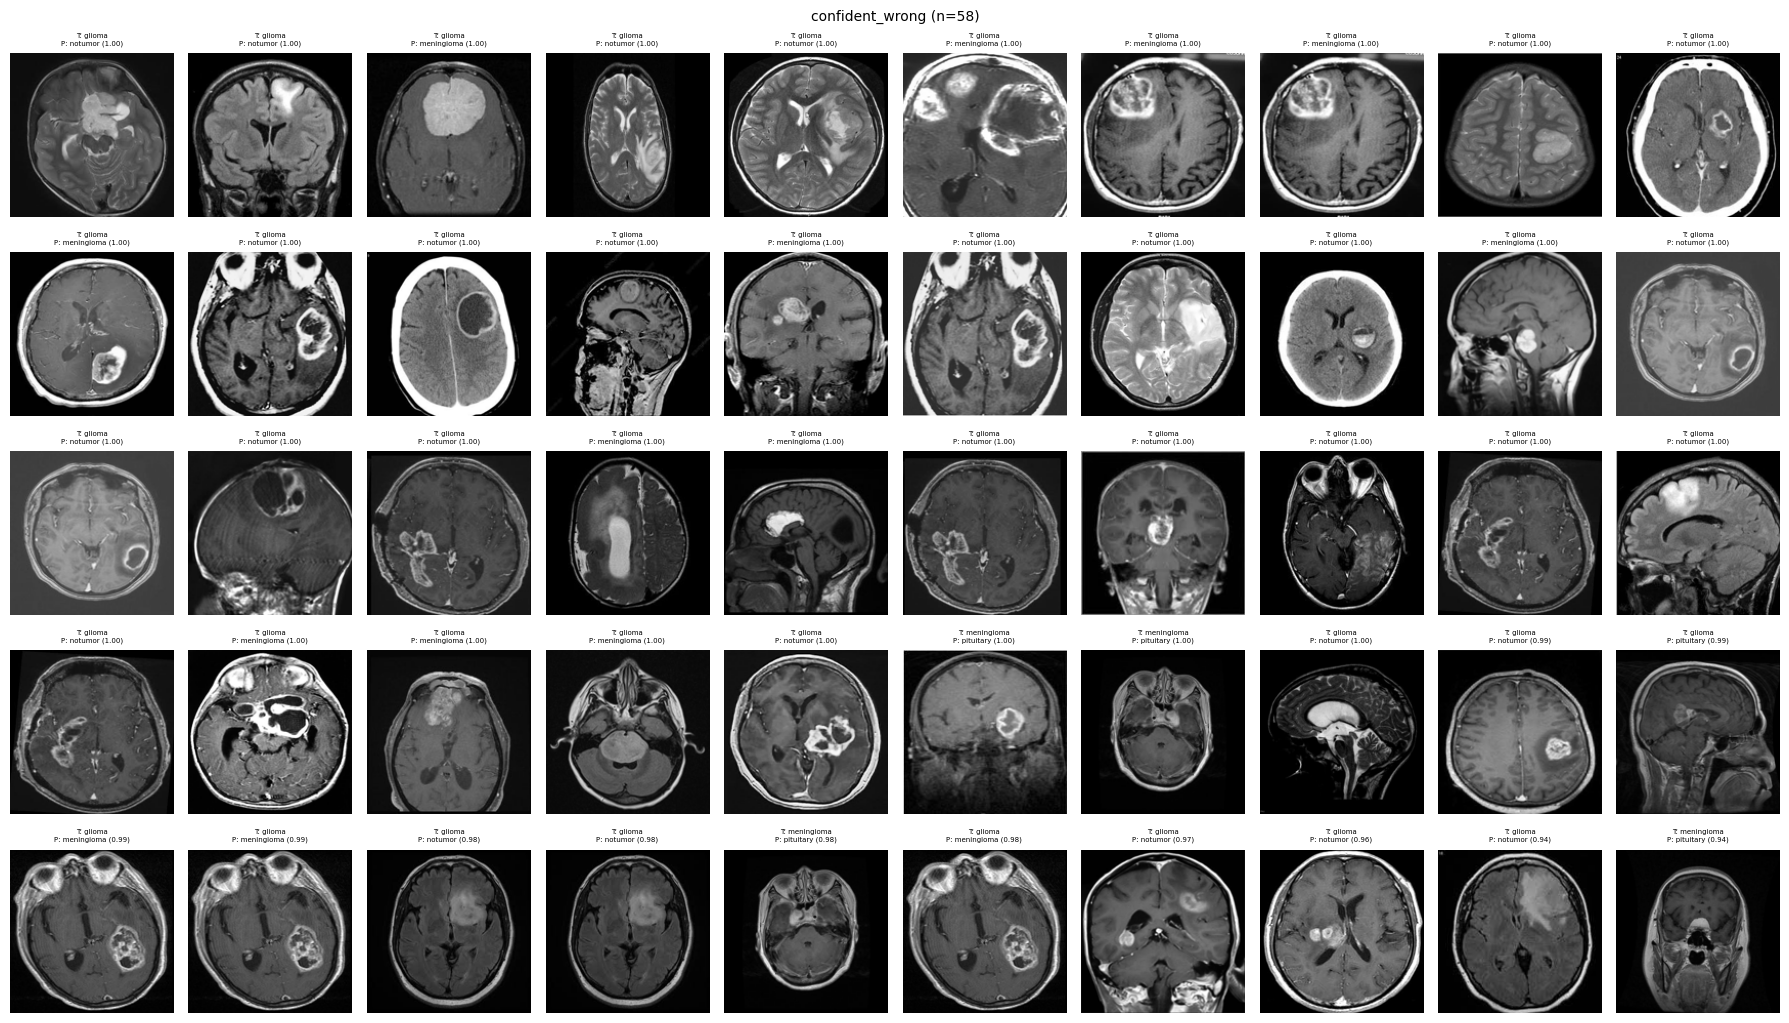

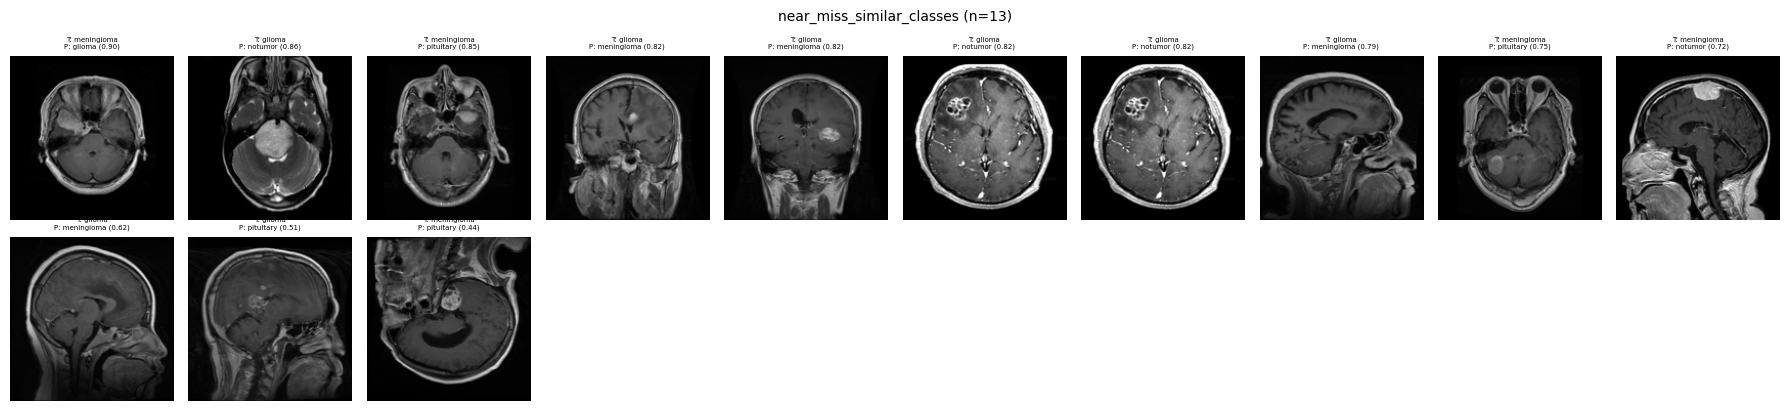

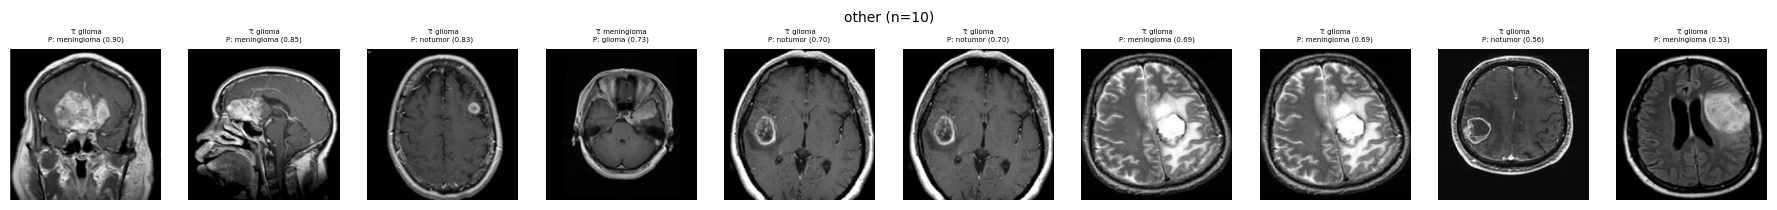

In [15]:
def save_grid(rows, fname, cols=10, title=None):
    r = int(np.ceil(len(rows) / cols))
    fig, axes = plt.subplots(r, cols, figsize=(cols*1.8, r*2.1))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, row) in zip(axes.ravel(), rows.iterrows()):
        ax.imshow(Image.open(row.path).convert("RGB").resize((160, 160)))
        ax.set_title(f"T: {row.true_name}\nP: {row.pred_name} ({row.conf:.2f})", fontsize=5)
    if title: fig.suptitle(title, fontsize=10)
    fig.tight_layout(); fig.savefig(OUT/fname, dpi=200); plt.show()

for c, g in err.groupby("cause"):
    save_grid(g.sort_values("conf", ascending=False).head(50),
              f"errors_{c}.png", title=f"{c} (n={len(g)})")

In [16]:
logits = torch.tensor(np.load(OUT/"test_logits.npy"))
labels = torch.tensor(np.load(OUT/"test_labels.npy"))
cal_idx  = np.load(OUT/"cal_idx.npy")
eval_idx = np.load(OUT/"eval_idx.npy")

cal_logits,  cal_labels  = logits[cal_idx],  labels[cal_idx]
eval_logits, eval_labels = logits[eval_idx], labels[eval_idx]
print(len(cal_idx), "calibration images |", len(eval_idx), "evaluation images")

800 calibration images | 800 evaluation images


In [17]:
def ece_bins(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece, acc, cf, cnt = 0.0, [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        cnt.append(int(m.sum()))
        if m.any():
            a, c = correct[m].mean().item(), conf[m].mean().item()
            ece += m.float().mean().item() * abs(a - c)
        else:
            a = c = float("nan")
        acc.append(a); cf.append(c)
    return ece, np.array(acc), np.array(cf), np.array(cnt), edges.numpy()

In [18]:
probs_before = torch.nn.functional.softmax(eval_logits, 1)
ece_b = ece_bins(probs_before, eval_labels)[0]
nll_b = torch.nn.functional.cross_entropy(eval_logits, eval_labels).item()
acc   = (eval_logits.argmax(1) == eval_labels).float().mean().item()
print(f"Accuracy {acc:.4f} | ECE {ece_b:.4f} | NLL {nll_b:.4f}")

Accuracy 0.9488 | ECE 0.0431 | NLL 0.6733


In [19]:
log_t = torch.nn.Parameter(torch.zeros(1))          # T = exp(0) = 1 to start
opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

def closure():
    opt.zero_grad()
    loss = torch.nn.functional.cross_entropy(cal_logits / log_t.exp(), cal_labels)
    loss.backward()
    return loss

opt.step(closure)
T = log_t.exp().item()
print(f"Temperature T = {T:.3f}")

Temperature T = 3.568


In [20]:
probs_after = torch.nn.functional.softmax(eval_logits / T, 1)
ece_a = ece_bins(probs_after, eval_labels)[0]
nll_a = torch.nn.functional.cross_entropy(eval_logits / T, eval_labels).item()
acc_a = (probs_after.argmax(1) == eval_labels).float().mean().item()

print(f"          Before    After")
print(f"ECE      {ece_b:.4f}   {ece_a:.4f}")
print(f"NLL      {nll_b:.4f}   {nll_a:.4f}")
print(f"Accuracy {acc:.4f}   {acc_a:.4f}   (must be identical)")

wrong = eval_logits.argmax(1) != eval_labels
print(f"Mean confidence on errors: {probs_before.max(1).values[wrong].mean():.3f} -> "
      f"{probs_after.max(1).values[wrong].mean():.3f}")

          Before    After
ECE      0.0431   0.0228
NLL      0.6733   0.2719
Accuracy 0.9488   0.9488   (must be identical)
Mean confidence on errors: 0.913 -> 0.734


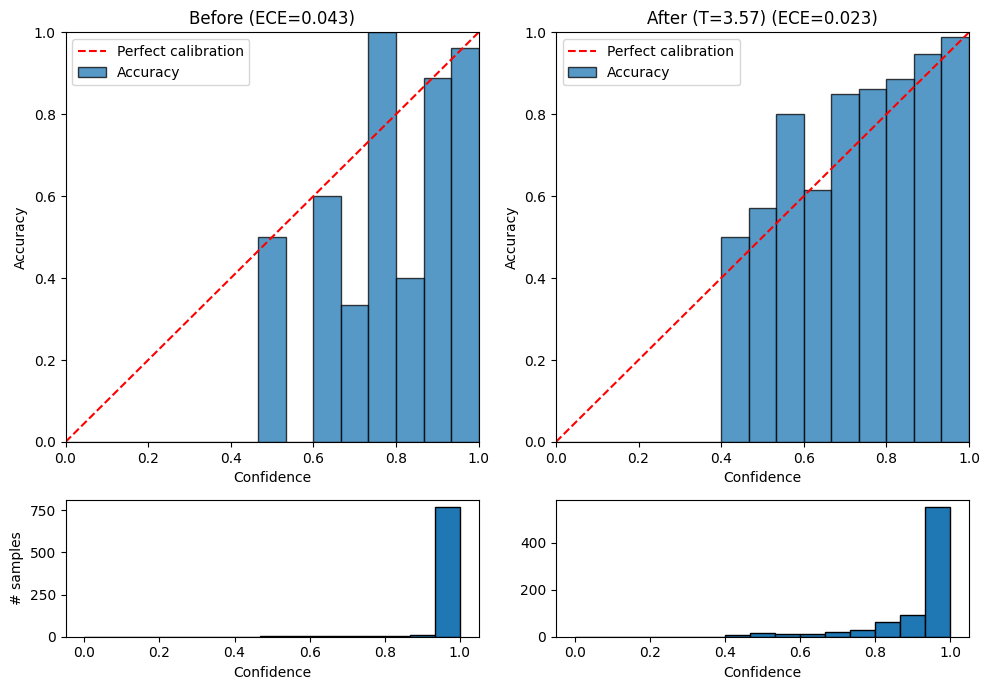

In [21]:
def reliability(ax, probs, title):
    ece, acc, cf, cnt, edges = ece_bins(probs, eval_labels)
    c = (edges[:-1] + edges[1:]) / 2
    ax.bar(c, np.nan_to_num(acc), width=1/15, edgecolor="k", alpha=0.75, label="Accuracy")
    ax.plot([0, 1], [0, 1], "r--", label="Perfect calibration")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Confidence", ylabel="Accuracy",
           title=f"{title} (ECE={ece:.3f})")
    ax.legend(loc="upper left")
    return c, cnt

fig, axes = plt.subplots(2, 2, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
c, cnt_b = reliability(axes[0, 0], probs_before, "Before")
c, cnt_a = reliability(axes[0, 1], probs_after, f"After (T={T:.2f})")
axes[1, 0].bar(c, cnt_b, width=1/15, edgecolor="k"); axes[1, 0].set_ylabel("# samples")
axes[1, 1].bar(c, cnt_a, width=1/15, edgecolor="k")
for a in axes[1]: a.set_xlabel("Confidence")
fig.tight_layout(); fig.savefig(OUT/"reliability_diagram.png", dpi=200); plt.show()

In [22]:
(OUT/"calibration.txt").write_text(
    f"T={T:.4f}\nECE before={ece_b:.4f} after={ece_a:.4f}\n"
    f"NLL before={nll_b:.4f} after={nll_a:.4f}\n")
np.save(OUT/"temperature.npy", np.array([T]))